# Exploitation vs Exploration

In [1]:
import numpy as np
import matplotlib.pyplot as plt
!pip install bayesian-optimization==1.5.1
from bayes_opt import BayesianOptimization
from bayes_opt import UtilityFunction

# Target function

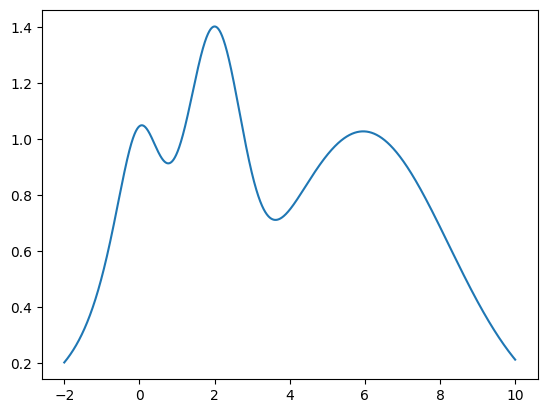

In [2]:
np.random.seed(42)
xs = np.linspace(-2, 10, 10000)

def f(x):
    return np.exp(-(x - 2) ** 2) + np.exp(-(x - 6) ** 2 / 10) + 1/ (x ** 2 + 1)

plt.plot(xs, f(xs))
plt.show()

## Utility function for plotting

In [6]:
def plot_bo(f, bo):
    x = np.linspace(-2, 10, 10000)
    mean, sigma = bo._gp.predict(x.reshape(-1, 1), return_std=True)

    plt.figure(figsize=(16, 9))
    plt.plot(x, f(x), label = 'True function')
    plt.plot(x, mean, label = 'Predicted mean')
    plt.fill_between(x, mean + sigma, mean - sigma, alpha=0.1)
    plt.scatter(bo.space.params.flatten(), bo.space.target, c="red", s=50, zorder=10)
    plt.legend()
    plt.show()

# Acquisition Function "Upper Confidence Bound"

Upper confidence bound (UCB) is a popular acquisition function used in Bayesian optimization. It is based on the Gaussian process model of the objective function, similar to PI and EI.

UCB selects the next point to evaluate based on an upper confidence bound on the true function value at that point. Specifically, UCB at a point x is given by:

UCB(x) = μ(x) + κσ(x)

where μ(x) is the predicted mean of the function at x based on the Gaussian process model, σ(x) is the predicted standard deviation of the function at x, and κ is a user-defined parameter that controls the trade-off between exploration and exploitation.

In other words, UCB(x) calculates an upper bound on the true function value at x by adding a multiple of the predicted standard deviation to the predicted mean. This encourages UCB to explore regions of the search space with high uncertainty (large σ(x)) and high potential for improvement (large μ(x)).

One advantage of UCB over PI and EI is that it allows for a more direct trade-off between exploration and exploitation. By adjusting the value of κ, we can control the degree of exploration vs exploitation. Additionally, UCB can be more effective than PI and EI in handling noisy objective functions or functions with multiple local optima.

One downside of UCB is that it can be overly conservative in regions of the search space with high uncertainty, leading to slower convergence.

## Prefer exploitation (kappa=0.1)

Note that most points are around the peak(s).

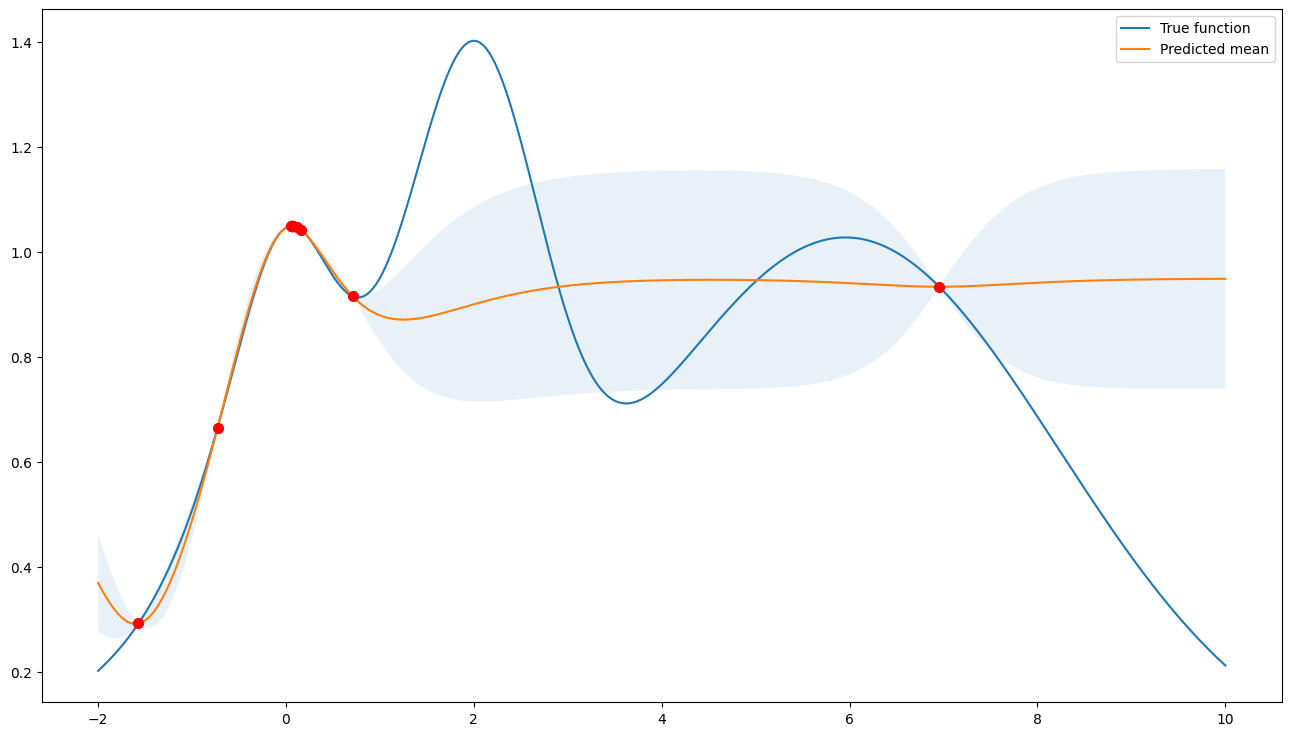

In [9]:
bo = BayesianOptimization(
    f=f,
    pbounds={"x": (-2, 10)},
    verbose=0,
    random_state=987234,
)

acquisition_function = UtilityFunction(kind="ucb", kappa=0.1)
bo.maximize(n_iter=10, acquisition_function=acquisition_function)

plot_bo(f, bo)

## Prefer exploration (kappa=10)

Note that the points are more spread out across the whole range.

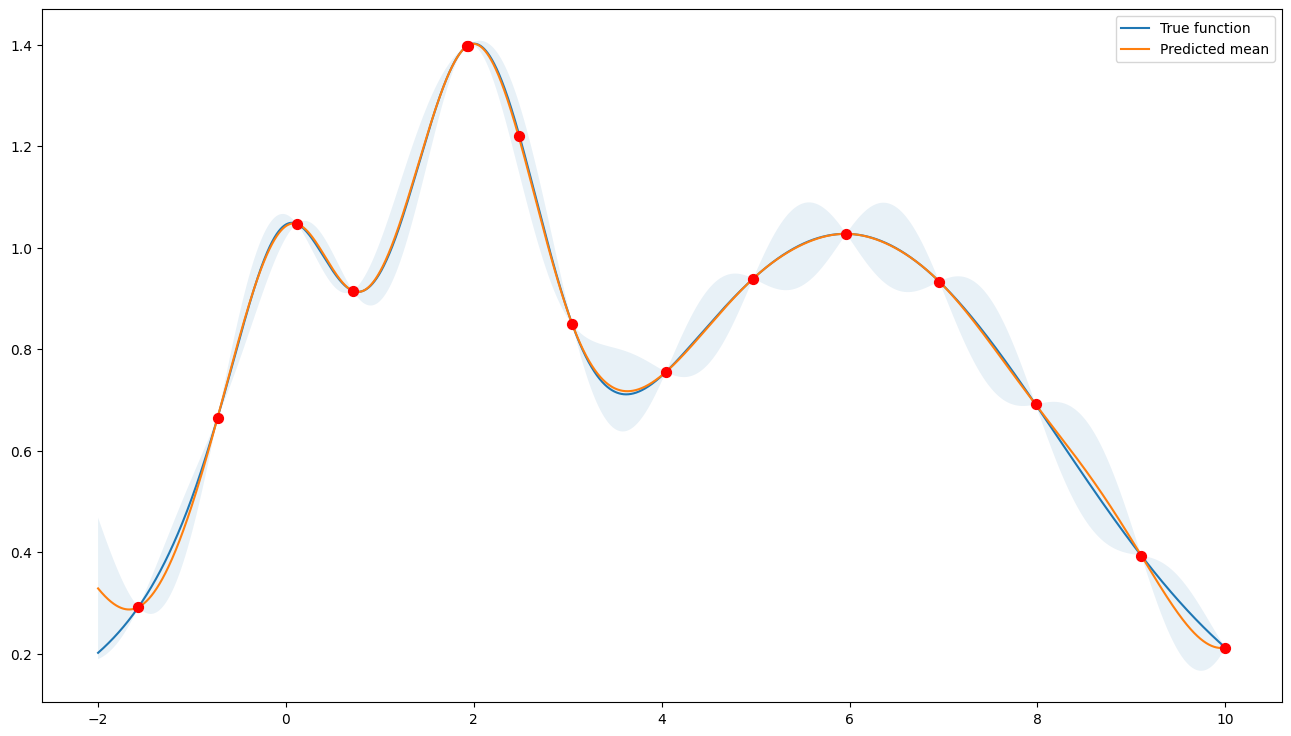

In [10]:
bo = BayesianOptimization(
    f=f,
    pbounds={"x": (-2, 10)},
    verbose=0,
    random_state=987234,
)

acquisition_function = UtilityFunction(kind="ucb", kappa=10)
bo.maximize(n_iter=10, acquisition_function=acquisition_function)

plot_bo(f, bo)

# Acquisition Function "Expected Improvement"

Expected improvement (EI) is another popular acquisition function used in Bayesian optimization. Like PI, it is also based on the Gaussian process model of the objective function.

The expected improvement at a point x is defined as the expected increase in the best observed value if we were to evaluate the function at x. Specifically, the EI at x is given by:

EI(x) = E[max(f(x) - f(x_best), 0)]

where f(x) is the predicted value of the function at x based on the Gaussian process model, x_best is the current best observed point, and E[.] denotes the expected value.

In other words, EI(x) calculates the expected improvement in the objective function value if we evaluate the function at x, and it favors points where the expected improvement is high.

One advantage of EI over PI is that it takes into account both the probability and the magnitude of improvement. As a result, it is more effective in balancing exploration and exploitation. Additionally, EI can handle uncertainty in the Gaussian process model more effectively than PI.

One downside of EI is that it can be computationally expensive to evaluate, as it involves optimizing an expensive analytical expression. However, various approximate methods have been developed to overcome this issue, such as Monte Carlo estimation and analytical approximations.

## The utility function is:

$$ EI(x) = (μ(x) - f(x^*) - \xi) \eta\left(\frac{μ(x) - f(x^*) - \xi}{σ(x)}\right)+σ(x)\theta \left(\frac{μ(x) - f(x^*) - \xi}{σ(x)}\right) $$

where $\eta$ and $\theta$ denotes the cumulative distribution function and density function of a standard Gaussian distribution.

## Prefer exploitation (xi=0.0)

Note that most points are around the peak(s).

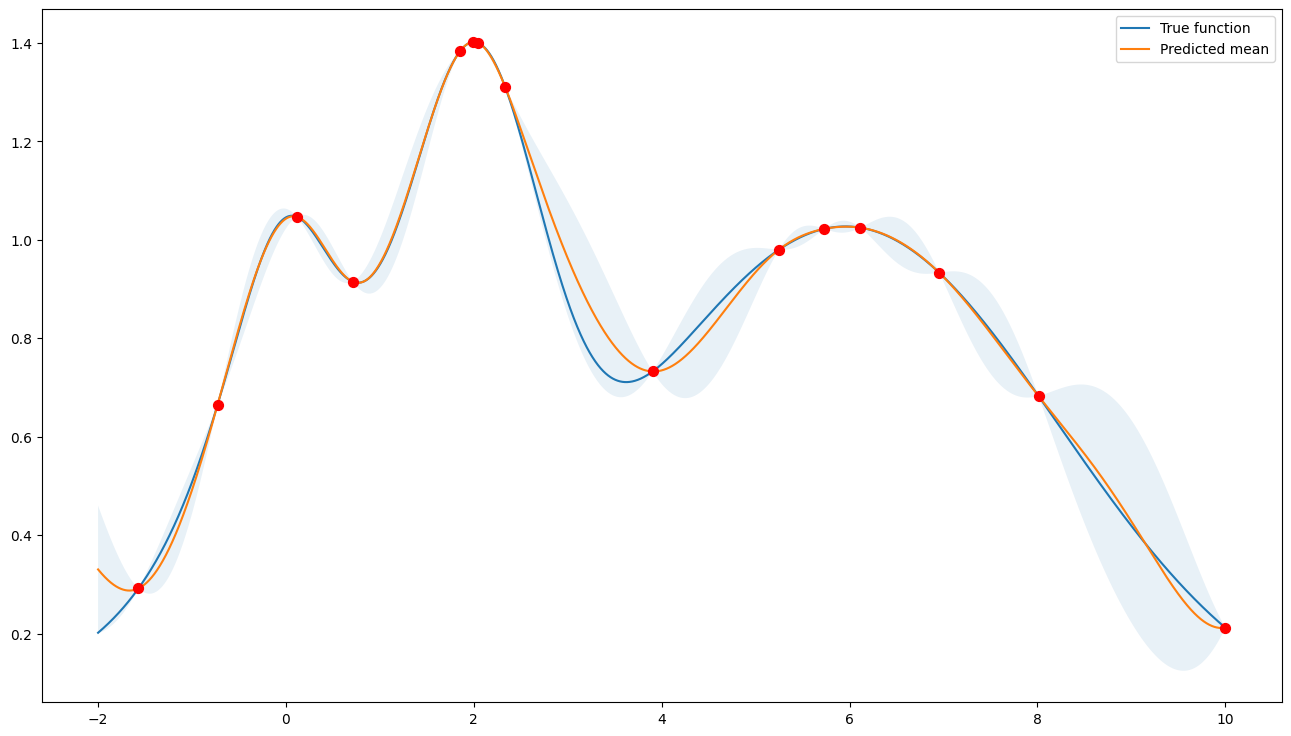

In [16]:
bo = BayesianOptimization(
    f=f,
    pbounds={"x": (-2, 10)},
    verbose=0,
    random_state=987234,
)

acquisition_function = UtilityFunction(kind="ei", xi=1e-5)
bo.maximize(n_iter=10, acquisition_function=acquisition_function)

plot_bo(f, bo)

## Prefer exploration (xi=0.1)

Note that the points are more spread out across the whole range.

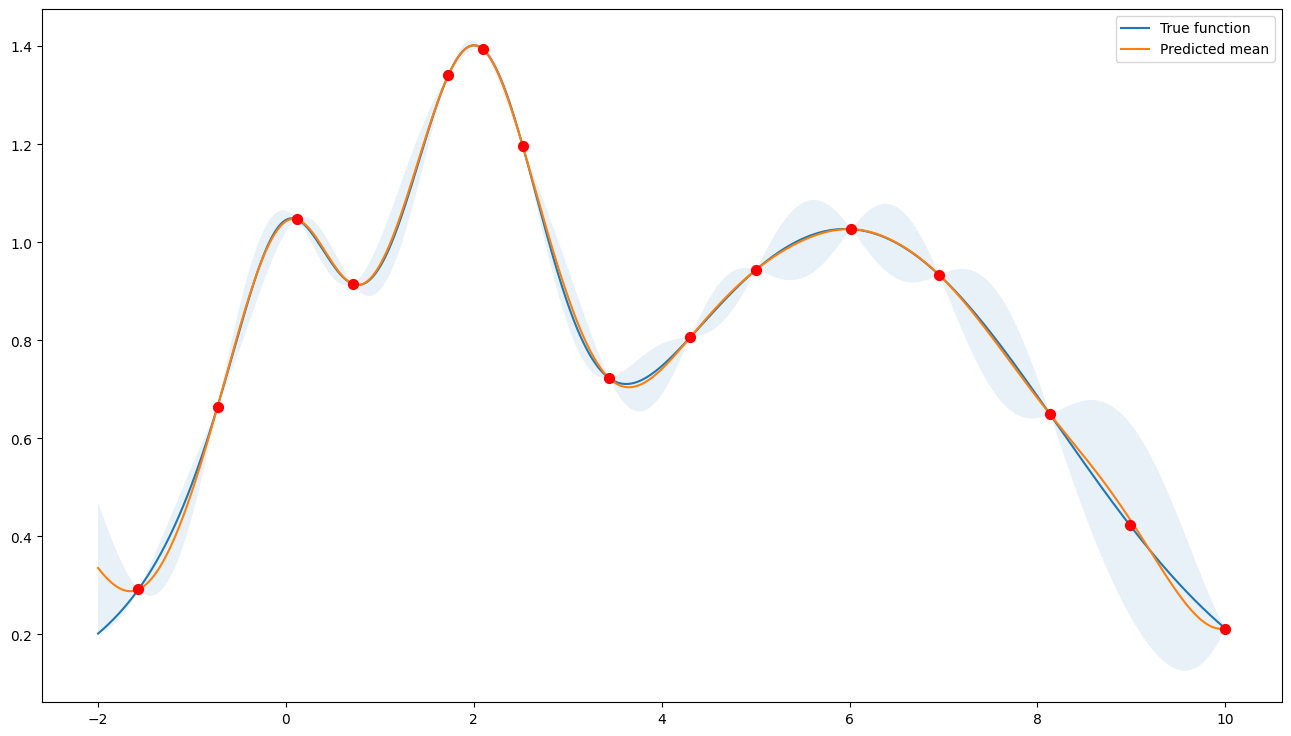

In [17]:
bo = BayesianOptimization(
    f=f,
    pbounds={"x": (-2, 10)},
    verbose=0,
    random_state=987234,
)

acquisition_function = UtilityFunction(kind="ei", xi=1e-1)
bo.maximize(n_iter=10, acquisition_function=acquisition_function)

plot_bo(f, bo)

# Acquisition Function "Probability of Improvement"

In Bayesian optimization, an acquisition function is used to determine which point to evaluate next. The probability of improvement (PI) is one such acquisition function.

The idea behind PI is to maximize the probability of improving upon the best observed value of the function so far. Specifically, given a Gaussian process model of the objective function, PI is defined as:

PI(x) = P(f(x) > f(x_best))

where x is the point at which we want to evaluate the function, f(x) is the predicted value of the function at x based on the Gaussian process model, and x_best is the best observed point so far.

In other words, PI(x) calculates the probability that evaluating the function at x will yield a better value than the current best value. This makes PI a "greedy" acquisition function, as it always selects the point with the highest probability of improvement.

One limitation of PI is that it can be overly confident in regions of the search space where the uncertainty of the Gaussian process model is high. To address this issue, other acquisition functions such as expected improvement and upper confidence bound are often used in conjunction with PI.

## THE Utility function is:

$$ PI(x) =  \eta\left(\frac{μ(x) - f(x^*) - \xi}{σ(x)}\right)$$

## Prefer exploitation (xi=1e-4)

Note that most points are around the peak(s).

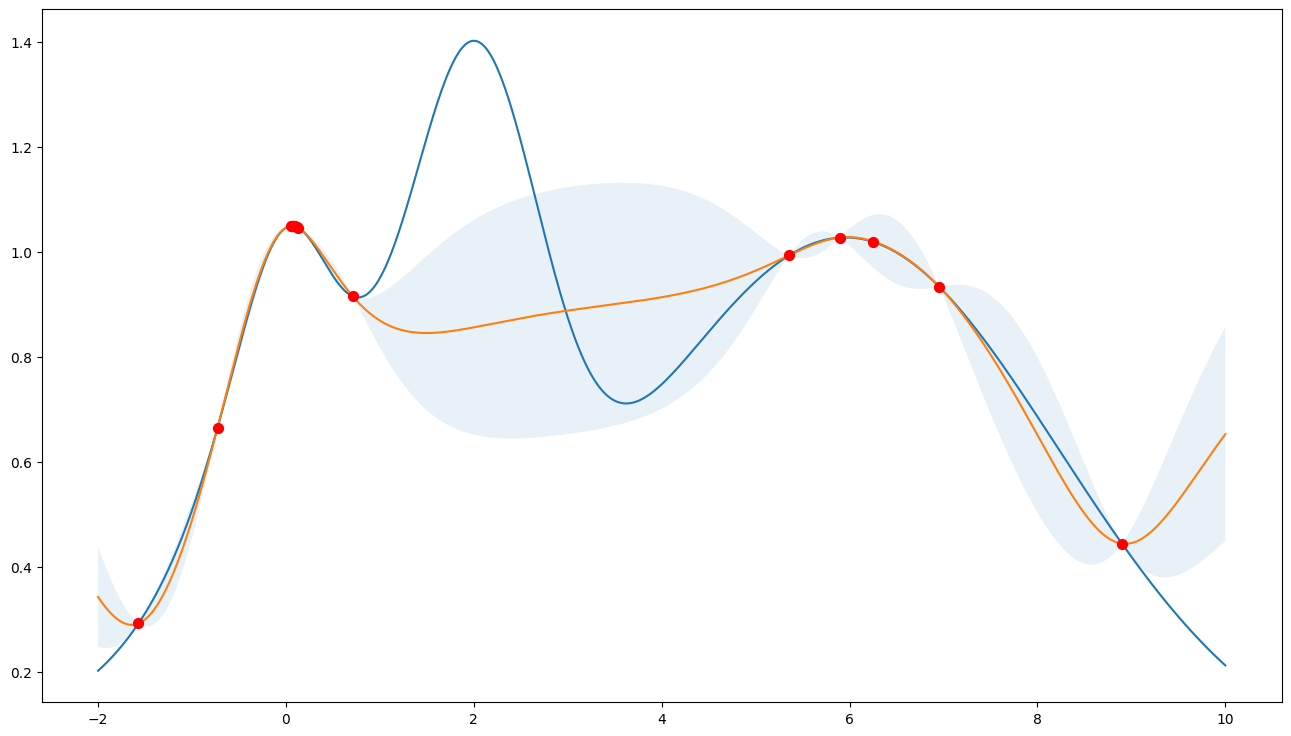

In [ ]:
bo = BayesianOptimization(
    f=f,
    pbounds={"x": (-2, 10)},
    verbose=0,
    random_state=987234,
)

acquisition_function = UtilityFunction(kind="poi", xi=1e-4)
bo.maximize(n_iter=10, acquisition_function=acquisition_function)

plot_bo(f, bo)

## Prefer exploration (xi=0.1)

Note that the points are more spread out across the whole range.

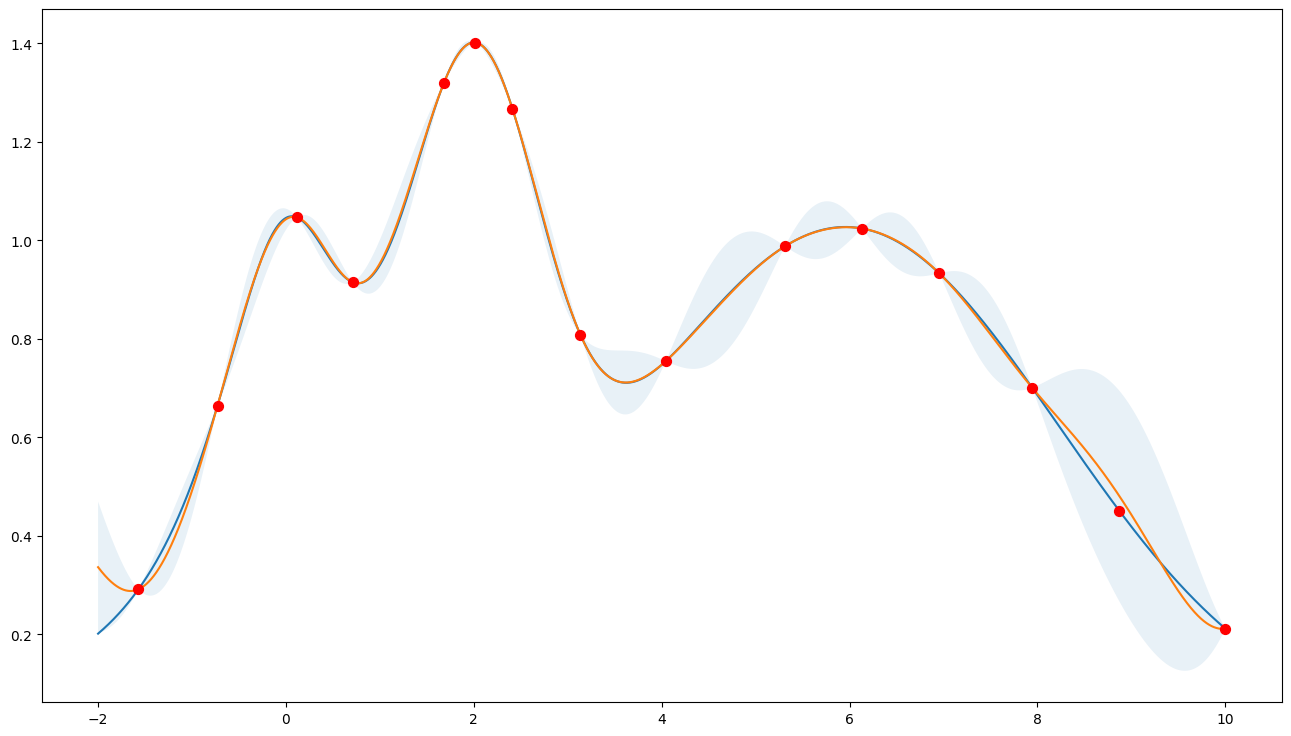

In [ ]:
bo = BayesianOptimization(
    f=f,
    pbounds={"x": (-2, 10)},
    verbose=0,
    random_state=987234,
)

acquisition_function = UtilityFunction(kind="poi", xi=1e-1)
bo.maximize(n_iter=10, acquisition_function=acquisition_function)

plot_bo(f, bo)

## 1.  Expected Improvement (EI) — Good general-purpose choice
### Use when:

You want a balanced strategy that considers both improvement and uncertainty.

The objective function is moderately expensive to evaluate.

You're optimizing a noisy or black-box function.

Why choose it:

It’s robust, widely supported in libraries, and often a default for good reason.

It’s more conservative than UCB, but more exploratory than PI.

##  2. Upper Confidence Bound (UCB) — Exploration-focused
### Use when:

You want more aggressive exploration (especially early in optimization).

You believe the function has multiple modes (local optima).

You have a relatively high evaluation budget.

Why choose it:

The hyperparameter
𝜅
κ directly controls the trade-off.

Theoretically grounded in regret bounds (especially in Gaussian process UCB algorithms).

Watch out:

Needs careful tuning of
𝜅
κ — too high: pure exploration, too low: greedy.

##  3. Probability of Improvement (PI) — Greedy exploitation
### Use when:

You are near convergence and want to fine-tune around the current best.

You trust your surrogate model (e.g., GP) and have low model uncertainty.

Why choose it:

Fast to compute and simple.

Encourages exploitation (may miss global optima if not careful).

Watch out:

Very sensitive to the trade-off parameter
𝜉
ξ, and not good at exploring.

